# Lab Exercise: Generative Adversarial Networks

**Dataset:** MVTec AD — Bottle  

**Framework:** TensorFlow / Keras  

**Author:** Maritza Elizabeth Albán Escobar  

## Objective

The objective of this laboratory is to develop and evaluate a Generative Adversarial Network (GAN) for image generation and anomaly detection using the MVTec AD dataset.

The laboratory includes the following objectives:

1. **Build a Generator** capable of producing synthetic bottle images from random latent vectors.

2. **Build a Discriminator** as a binary classifier to distinguish real images from generated images.

3. **Train the GAN** by alternately optimizing the Discriminator and Generator through adversarial learning.

4. **Evaluate the trained Discriminator** as a potential anomaly detector using real test images containing defect-free and defective bottles.

5. **Analyze the generated images and discriminator scores** to investigate the relationship between image generation, adversarial learning, and anomaly detection.

# 1. Dataset

The MVTec AD Bottle category is used in this laboratory to investigate image generation and anomaly detection.

The Generator is trained using defect-free bottle images as real samples, while the Discriminator learns to distinguish real images from generated images. The test set contains both defect-free images and images with different types of defects, which are used to evaluate the Discriminator as a potential anomaly detector.

In [2]:
# ==========================================
# 1.1 IMPORT LIBRARIES AND MOUNT GOOGLE DRIVE
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

# Mount Google Drive
from pathlib import Path

# Display TensorFlow version
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
# ==========================================
# 1.2 DEFINE DATASET PATH AND PARAMETERS
# ==========================================

DATA_DIR = Path("bottle")

IMG_SIZE = (128, 128)
CHANNELS = 3
BATCH_SIZE = 16

print("Dataset path:", DATA_DIR)

# ==========================================
# 1.3 LOAD REAL TRAINING IMAGES
# ==========================================

TRAIN_DIR = DATA_DIR / "train" / "good"

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("Training directory:", TRAIN_DIR)
print("Number of batches:", tf.data.experimental.cardinality(train_dataset).numpy())

# ==========================================
# 1.4 NORMALIZE REAL IMAGES
# ==========================================

def normalize_images(images):
    images = tf.cast(images, tf.float32) / 255.0
    return images

train_dataset = train_dataset.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


Dataset path: bottle
Found 209 files.


W0000 00:00:1791230111.695662   48595 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791230111.731041   48595 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791230112.104682   48595 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Training directory: bottle/train/good
Number of batches: 14


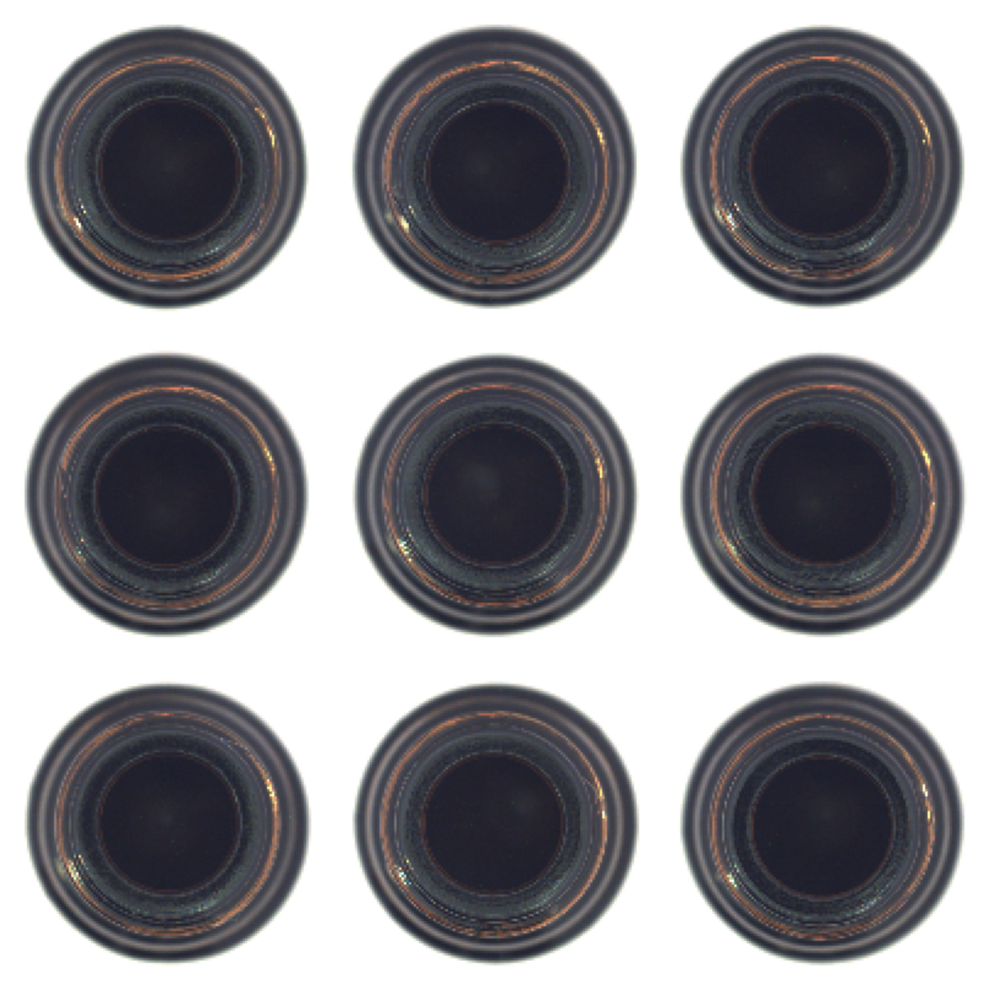

In [4]:
# ==========================================
# 1.5 VISUALIZE REAL IMAGES
# ==========================================

for images in train_dataset.take(1):
    plt.figure(figsize=(10, 10))

    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Dataset Analysis

The training dataset contains 209 defect-free bottle images organized into 14 batches. The images are resized to 128 × 128 pixels and normalized to the [0, 1] range, providing a consistent representation for the real samples used during adversarial training.

The visual inspection confirms that the training images represent defect-free bottles with consistent image dimensions and appearance. These images will be used as the real samples for training the Discriminator.

# 2. Generator

The Generator learns to transform random latent vectors into synthetic bottle images. Its architecture progressively increases the spatial resolution of the latent representation until reaching the target image size of 128 × 128 × 3.

In [5]:
# ==========================================
# 2.1 DEFINE GENERATOR PARAMETERS
# ==========================================

LATENT_DIM = 128

print("Latent vector dimension:", LATENT_DIM)
print("Generator output shape:", (*IMG_SIZE, CHANNELS))

# ==========================================
# 2.2 BUILD THE GENERATOR
# ==========================================

generator = models.Sequential(name="Generator")

generator.add(layers.Input(shape=(LATENT_DIM,)))

# Project latent vector into a spatial representation
generator.add(layers.Dense(16 * 16 * 128))
generator.add(layers.Reshape((16, 16, 128)))

# Upsampling: 16x16 -> 32x32
generator.add(layers.Conv2DTranspose(
    64, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# Upsampling: 32x32 -> 64x64
generator.add(layers.Conv2DTranspose(
    32, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# Upsampling: 64x64 -> 128x128
generator.add(layers.Conv2DTranspose(
    16, kernel_size=4, strides=2, padding="same"
))
generator.add(layers.BatchNormalization())
generator.add(layers.ReLU())

# RGB output
generator.add(layers.Conv2D(
    CHANNELS,
    kernel_size=3,
    padding="same",
    activation="sigmoid"
))

generator.summary()

Latent vector dimension: 128
Generator output shape: (128, 128, 3)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 64, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 128, 128, 16)   │         8,208 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128, 128, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128, 128, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 3)    │           435 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,400,099 (16.79 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 224 (896.00 B)

I0000 00:00:1791230126.650923   48595 cuda_dnn.cc:461] Loaded cuDNN version 92700


Latent vector shape: (1, 128)
Generated image shape: (1, 128, 128, 3)
Pixel range: 0.49389341473579407 to 0.5063672661781311


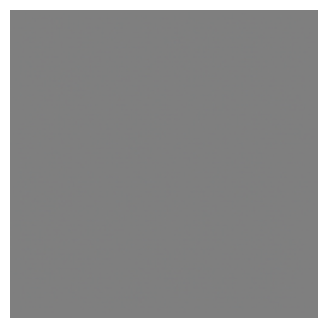

In [6]:
# ==========================================
# 2.3 GENERATE AN UNTRAINED IMAGE
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

generated_image = generator(z, training=False)

print("Latent vector shape:", z.shape)
print("Generated image shape:", generated_image.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(generated_image)),
    "to",
    float(tf.reduce_max(generated_image))
)

# ==========================================
# 2.4 VISUALIZE UNTRAINED OUTPUT
# ==========================================

plt.figure(figsize=(4, 4))
plt.imshow(generated_image[0])
plt.axis("off")
plt.show()

###Generator Analysis

The Generator receives a 128-dimensional random latent vector and transforms it into a 128 × 128 × 3 RGB image through a sequence of learned layers. Before training, the generated output does not contain meaningful bottle structures, as the network weights have not yet learned the characteristics of the real dataset. The sigmoid output constrains the generated pixel values to the [0, 1] range.

#3. Discriminator

The Discriminator is a convolutional binary classifier that learns to distinguish real bottle images from images generated by the Generator. It receives an RGB image of size 128 × 128 and produces a single realness score in the [0, 1] range.

In [7]:
# ==========================================
# 3.1 BUILD THE DISCRIMINATOR
# ==========================================

discriminator = models.Sequential(name="Discriminator")

discriminator.add(layers.Input(
    shape=(*IMG_SIZE, CHANNELS)
))

# Feature extraction
discriminator.add(layers.Conv2D(
    32, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

discriminator.add(layers.Conv2D(
    64, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.BatchNormalization())
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

discriminator.add(layers.Conv2D(
    128, kernel_size=4, strides=2, padding="same"
))
discriminator.add(layers.BatchNormalization())
discriminator.add(layers.LeakyReLU(negative_slope=0.2))

# Classification
discriminator.add(layers.Flatten())
discriminator.add(layers.Dense(1, activation="sigmoid"))

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,137 (777.88 KB)

 Trainable params: 198,753 (776.38 KB)

 Non-trainable params: 384 (1.50 KB)

In [8]:
# ==========================================
# 3.2 TEST THE UNTRAINED DISCRIMINATOR
# ==========================================

# Get one real image
real_images = next(iter(train_dataset))
real_image = real_images[:1]

# Generate one fake image
z = tf.random.normal((1, LATENT_DIM))
fake_image = generator(z, training=False)

# Discriminator predictions
real_score = discriminator(real_image, training=False)
fake_score = discriminator(fake_image, training=False)

print("Real image score:", float(real_score[0, 0]))
print("Generated image score:", float(fake_score[0, 0]))

# ==========================================
# 3.3 COMPILE THE DISCRIMINATOR
# ==========================================

discriminator.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

Real image score: 0.5289444923400879
Generated image score: 0.5065332055091858


###Discriminator Analysis

The Discriminator is implemented as a convolutional binary classifier that maps a 128 × 128 × 3 image to a single realness score. Convolutional layers extract visual features while the final sigmoid activation converts the classification output into a value between 0 and 1. Before training, the predictions do not yet represent reliable real/fake discrimination because the network has not learned from the dataset.

#GAN Architecture

The Generator and Discriminator are connected to form the adversarial architecture. The Generator receives a latent vector and produces a synthetic image, which is then evaluated by the Discriminator. This combined model allows the Generator to receive feedback from the Discriminator during training.

In [9]:
# ==========================================
# 4.1 CONNECT GENERATOR AND DISCRIMINATOR
# ==========================================

discriminator.trainable = False

gan = models.Sequential(
    [generator, discriminator],
    name="GAN"
)

gan.summary()


Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 128, 128, 3)    │     4,400,099 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,599,236 (17.54 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 199,361 (778.75 KB)

In [10]:
# ==========================================
# 4.2 COMPILE THE GAN
# ==========================================

gan.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0002),
    loss="binary_crossentropy"
)

gan.summary()

Model: "GAN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator (Sequential)          │ (None, 128, 128, 3)    │     4,400,099 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,599,236 (17.54 MB)

 Trainable params: 4,399,875 (16.78 MB)

 Non-trainable params: 199,361 (778.75 KB)

In [11]:
# ==========================================
# 4.3 TEST THE COMBINED GAN
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

gan_output = gan(z, training=False)

print("Latent vector shape:", z.shape)
print("GAN output shape:", gan_output.shape)
print("Discriminator score:", float(gan_output[0, 0]))

Latent vector shape: (1, 128)
GAN output shape: (1, 1)
Discriminator score: 0.5065575242042542


### GAN Architecture Analysis

The Generator and Discriminator are successfully connected in a single adversarial model. The Generator transforms a latent vector into a synthetic image, while the frozen Discriminator evaluates its realness.

The combined model produces a single discriminator score from each latent vector. Before training, the observed score is close to 0.5, which is expected because the Discriminator has not yet learned to distinguish real and generated images.

The model configuration confirms that the Generator remains trainable while the Discriminator is frozen during Generator optimization. This configuration allows gradients to propagate through the Discriminator while updating only the Generator parameters.



# 5. GAN Training

The GAN is trained through alternating optimization of the Discriminator and Generator. The Discriminator learns to distinguish real images from generated images, while the Generator is optimized to produce images that the Discriminator classifies as real.

In [12]:
# ==========================================
# 5.1 DEFINE TRAINING PARAMETERS
# ==========================================

EPOCHS = 50

# Fixed latent vectors for monitoring Generator progress
FIXED_Z = tf.random.normal((9, LATENT_DIM))

# Store training history
d_losses = []
d_accuracies = []
g_losses = []

print("Number of epochs:", EPOCHS)
print("Fixed latent vectors shape:", FIXED_Z.shape)

# ==========================================
# 5.2 ADVERSARIAL TRAINING LOOP
# ==========================================

for epoch in range(EPOCHS):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        # Current batch size
        current_batch_size = tf.shape(real_images)[0]

        # ------------------------------------------
        # Train Discriminator
        # ------------------------------------------

        # Generate fake images
        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        fake_images = generator(
            z,
            training=True
        )

        # Labels:
        # Real images -> 1
        # Fake images -> 0
        real_labels = tf.ones(
            (current_batch_size, 1)
        )

        fake_labels = tf.zeros(
            (current_batch_size, 1)
        )

        # Combine real and fake samples
        combined_images = tf.concat(
            [real_images, fake_images],
            axis=0
        )

        combined_labels = tf.concat(
            [real_labels, fake_labels],
            axis=0
        )

        # Enable Discriminator training
        discriminator.trainable = True

        d_loss, d_accuracy = discriminator.train_on_batch(
            combined_images,
            combined_labels
        )

        # ------------------------------------------
        # Train Generator
        # ------------------------------------------

        # Freeze Discriminator weights
        discriminator.trainable = False

        # Generate a new batch of latent vectors
        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        # Generator target is 1:
        # it wants the Discriminator to classify
        # generated images as real
        generator_targets = tf.ones(
            (current_batch_size, 1)
        )

        g_loss = gan.train_on_batch(
            z,
            generator_targets
        )

        # Store batch results
        epoch_d_losses.append(float(d_loss))
        epoch_d_accuracies.append(float(d_accuracy))
        epoch_g_losses.append(float(g_loss))

    # Average results for the epoch
    mean_d_loss = np.mean(epoch_d_losses)
    mean_d_accuracy = np.mean(epoch_d_accuracies)
    mean_g_loss = np.mean(epoch_g_losses)

    d_losses.append(mean_d_loss)
    d_accuracies.append(mean_d_accuracy)
    g_losses.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Acc: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )

Number of epochs: 50
Fixed latent vectors shape: (9, 128)


I0000 00:00:1791230130.983963   48595 service.cc:153] XLA service 0x35ebc580 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791230130.984004   48595 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5060 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791230131.044874   48595 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791230135.623035   48595 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1791230138.011258   48595 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6491__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.28
I0000 00:00:1791230138.795734   49437 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to loca

Epoch 01/50 | D Loss: 0.0717 | D Acc: 0.9643 | G Loss: 0.5262
Epoch 02/50 | D Loss: 0.0020 | D Acc: 1.0000 | G Loss: 0.4125
Epoch 03/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 0.3674
Epoch 04/50 | D Loss: 0.0002 | D Acc: 1.0000 | G Loss: 0.4230
Epoch 05/50 | D Loss: 0.0011 | D Acc: 1.0000 | G Loss: 0.4963
Epoch 06/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 0.5310
Epoch 07/50 | D Loss: 0.0007 | D Acc: 1.0000 | G Loss: 0.4754
Epoch 08/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 0.4386
Epoch 09/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 0.4962
Epoch 10/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 0.5933
Epoch 11/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 0.7214
Epoch 12/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 1.0816
Epoch 13/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 1.5546
Epoch 14/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 2.0361
Epoch 15/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 2.4394
Epoch 16/50 | D Loss: 0.0002 | D Acc: 1.0000 | G Loss: 2.2990
Epoch 17

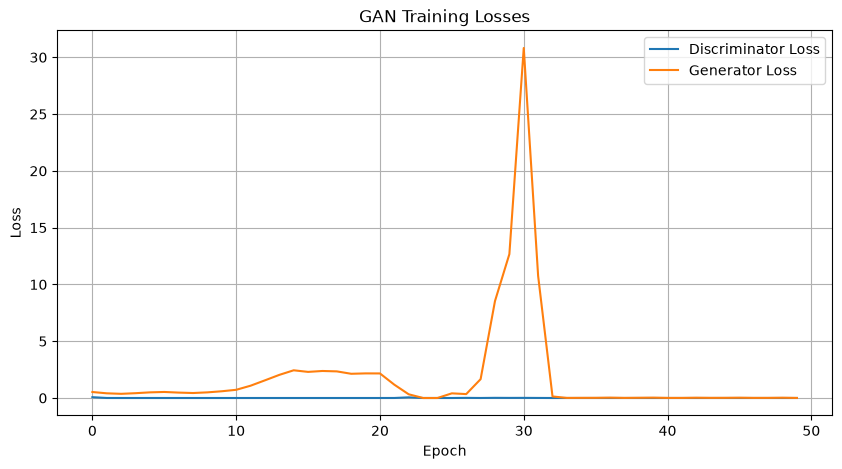

In [13]:
# ==========================================
# 5.3 PLOT GAN TRAINING LOSSES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(d_losses, label="Discriminator Loss")
plt.plot(g_losses, label="Generator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(True)

plt.show()

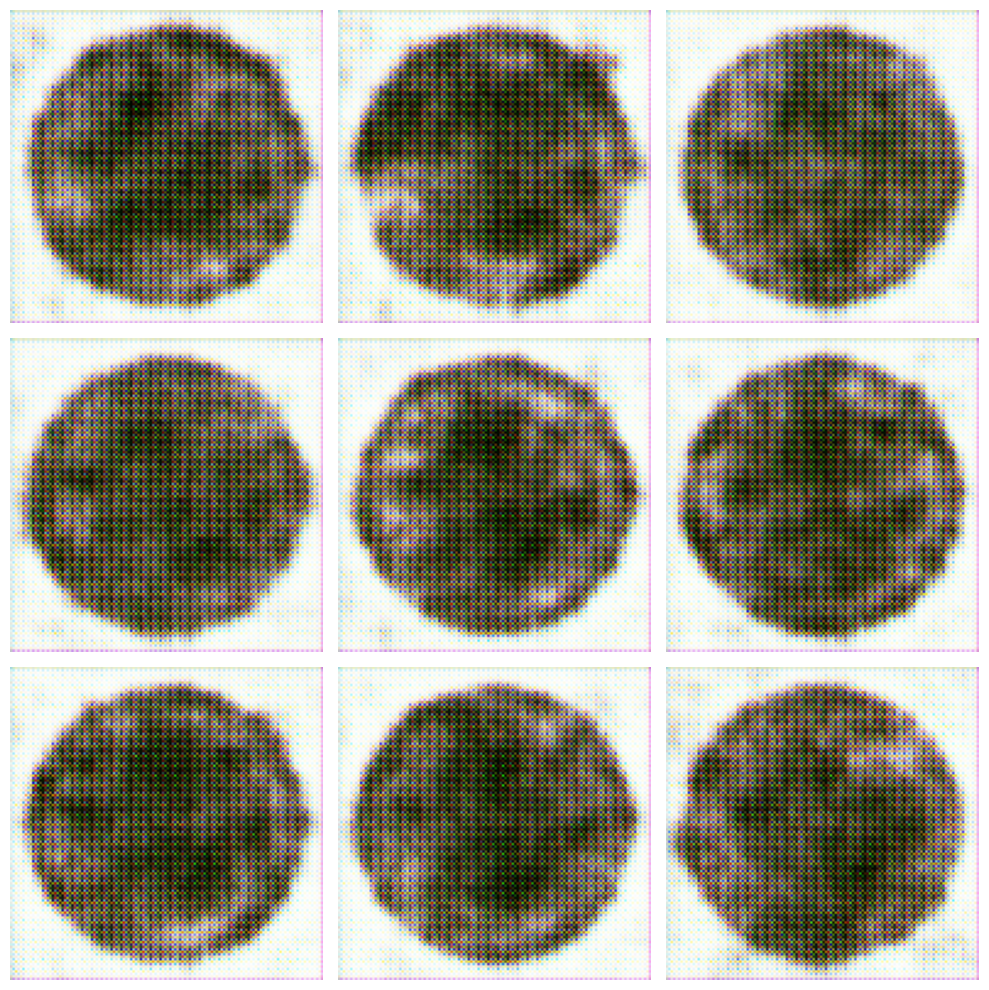

In [14]:
# ==========================================
# 5.4 VISUALIZE GENERATED IMAGES
# ==========================================

generated_images = generator(
    FIXED_Z,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# ==========================================
# 5.5 BUILD GENERATOR V2
# ==========================================

generator_v2 = models.Sequential(name="Generator_V2")

generator_v2.add(layers.Input(shape=(LATENT_DIM,)))

# Project latent vector into a rich spatial representation
generator_v2.add(layers.Dense(8 * 8 * 512))
generator_v2.add(layers.Reshape((8, 8, 512)))

# Upsampling: 8x8 -> 16x16
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    256,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 16x16 -> 32x32
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    128,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 32x32 -> 64x64
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    64,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# Upsampling: 64x64 -> 128x128
generator_v2.add(layers.UpSampling2D(size=(2, 2)))
generator_v2.add(layers.Conv2D(
    32,
    kernel_size=3,
    padding="same"
))
generator_v2.add(layers.BatchNormalization())
generator_v2.add(layers.ReLU())

# RGB output
generator_v2.add(layers.Conv2D(
    CHANNELS,
    kernel_size=3,
    padding="same",
    activation="sigmoid"
))

generator_v2.summary()

Model: "Generator_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 256)    │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,797,059 (22.11 MB)

 Trainable params: 5,796,099 (22.11 MB)

 Non-trainable params: 960 (3.75 KB)

In [16]:
# ==========================================
# 5.6 TEST UNTRAINED GENERATOR V2
# ==========================================

z = tf.random.normal((1, LATENT_DIM))

generated_image_v2 = generator_v2(
    z,
    training=False
)

print("Latent vector shape:", z.shape)
print("Generated image shape:", generated_image_v2.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(generated_image_v2)),
    "to",
    float(tf.reduce_max(generated_image_v2))
)

Latent vector shape: (1, 128)
Generated image shape: (1, 128, 128, 3)
Pixel range: 0.46094322204589844 to 0.525346577167511


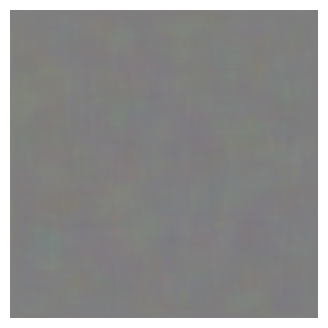

In [17]:
# ==========================================
# 5.7 VISUALIZE UNTRAINED GENERATOR V2
# ==========================================

plt.figure(figsize=(4, 4))

plt.imshow(generated_image_v2[0])
plt.axis("off")

plt.show()

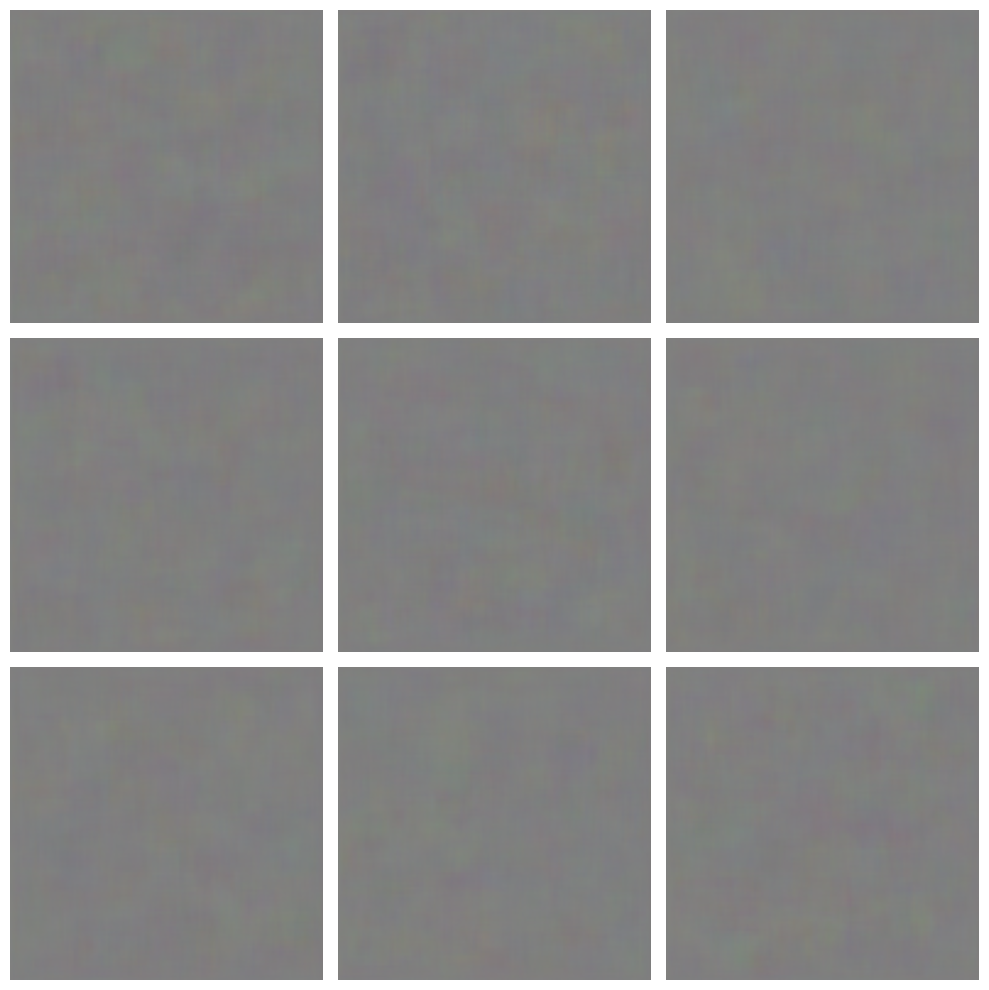

In [18]:
# ==========================================
# 5.8 TEST GENERATOR V2 WITH MULTIPLE LATENT VECTORS
# ==========================================

z = tf.random.normal((9, LATENT_DIM))

generated_images_v2 = generator_v2(
    z,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images_v2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# ==========================================
# 5.9 CONNECT GENERATOR V2 WITH DISCRIMINATOR
# ==========================================

# Freeze the Discriminator for Generator optimization
discriminator.trainable = False

gan_v2 = models.Sequential(
    [generator_v2, discriminator],
    name="GAN_V2"
)

gan_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0002
    ),
    loss="binary_crossentropy"
)

gan_v2.summary()

# ==========================================
# 5.10 TRAIN GAN V2
# ==========================================

EPOCHS_V2 = 50

d_losses_v2 = []
d_accuracies_v2 = []
g_losses_v2 = []

FIXED_Z_V2 = tf.random.normal((9, LATENT_DIM))

for epoch in range(EPOCHS_V2):

    epoch_d_losses = []
    epoch_d_accuracies = []
    epoch_g_losses = []

    for real_images in train_dataset:

        current_batch_size = tf.shape(real_images)[0]

        # ------------------------------------------
        # Train Discriminator
        # ------------------------------------------

        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        fake_images = generator_v2(
            z,
            training=True
        )

        real_labels = tf.ones(
            (current_batch_size, 1)
        )

        fake_labels = tf.zeros(
            (current_batch_size, 1)
        )

        combined_images = tf.concat(
            [real_images, fake_images],
            axis=0
        )

        combined_labels = tf.concat(
            [real_labels, fake_labels],
            axis=0
        )

        discriminator.trainable = True

        d_loss, d_accuracy = discriminator.train_on_batch(
            combined_images,
            combined_labels
        )

        # ------------------------------------------
        # Train Generator V2
        # ------------------------------------------

        discriminator.trainable = False

        z = tf.random.normal(
            (current_batch_size, LATENT_DIM)
        )

        generator_targets = tf.ones(
            (current_batch_size, 1)
        )

        g_loss = gan_v2.train_on_batch(
            z,
            generator_targets
        )

        epoch_d_losses.append(float(d_loss))
        epoch_d_accuracies.append(float(d_accuracy))
        epoch_g_losses.append(float(g_loss))

    mean_d_loss = np.mean(epoch_d_losses)
    mean_d_accuracy = np.mean(epoch_d_accuracies)
    mean_g_loss = np.mean(epoch_g_losses)

    d_losses_v2.append(mean_d_loss)
    d_accuracies_v2.append(mean_d_accuracy)
    g_losses_v2.append(mean_g_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_V2} | "
        f"D Loss: {mean_d_loss:.4f} | "
        f"D Acc: {mean_d_accuracy:.4f} | "
        f"G Loss: {mean_g_loss:.4f}"
    )

Model: "GAN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Generator_V2 (Sequential)       │ (None, 128, 128, 3)    │     5,797,059 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Discriminator (Sequential)      │ (None, 1)              │       199,137 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,996,196 (22.87 MB)

 Trainable params: 5,796,099 (22.11 MB)

 Non-trainable params: 200,097 (781.63 KB)

I0000 00:00:1791230175.676519   48595 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_138599__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.41


Epoch 01/50 | D Loss: 0.0000 | D Acc: 1.0000 | G Loss: 12.0552
Epoch 02/50 | D Loss: 0.0001 | D Acc: 1.0000 | G Loss: 9.3064
Epoch 03/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 12.9213
Epoch 04/50 | D Loss: 0.0001 | D Acc: 1.0000 | G Loss: 10.0225
Epoch 05/50 | D Loss: 0.0002 | D Acc: 1.0000 | G Loss: 5.9545
Epoch 06/50 | D Loss: 0.0014 | D Acc: 1.0000 | G Loss: 3.3920
Epoch 07/50 | D Loss: 0.0032 | D Acc: 1.0000 | G Loss: 0.3380
Epoch 08/50 | D Loss: 0.0024 | D Acc: 1.0000 | G Loss: 0.0066
Epoch 09/50 | D Loss: 0.0003 | D Acc: 1.0000 | G Loss: 0.1856
Epoch 10/50 | D Loss: 0.0001 | D Acc: 1.0000 | G Loss: 0.4337
Epoch 11/50 | D Loss: 0.0002 | D Acc: 1.0000 | G Loss: 0.3440
Epoch 12/50 | D Loss: 0.0006 | D Acc: 1.0000 | G Loss: 0.2478
Epoch 13/50 | D Loss: 0.0004 | D Acc: 1.0000 | G Loss: 0.4881
Epoch 14/50 | D Loss: 0.0005 | D Acc: 1.0000 | G Loss: 0.8196
Epoch 15/50 | D Loss: 0.0007 | D Acc: 1.0000 | G Loss: 2.3710
Epoch 16/50 | D Loss: 0.0024 | D Acc: 1.0000 | G Loss: 1.8683
Epoch

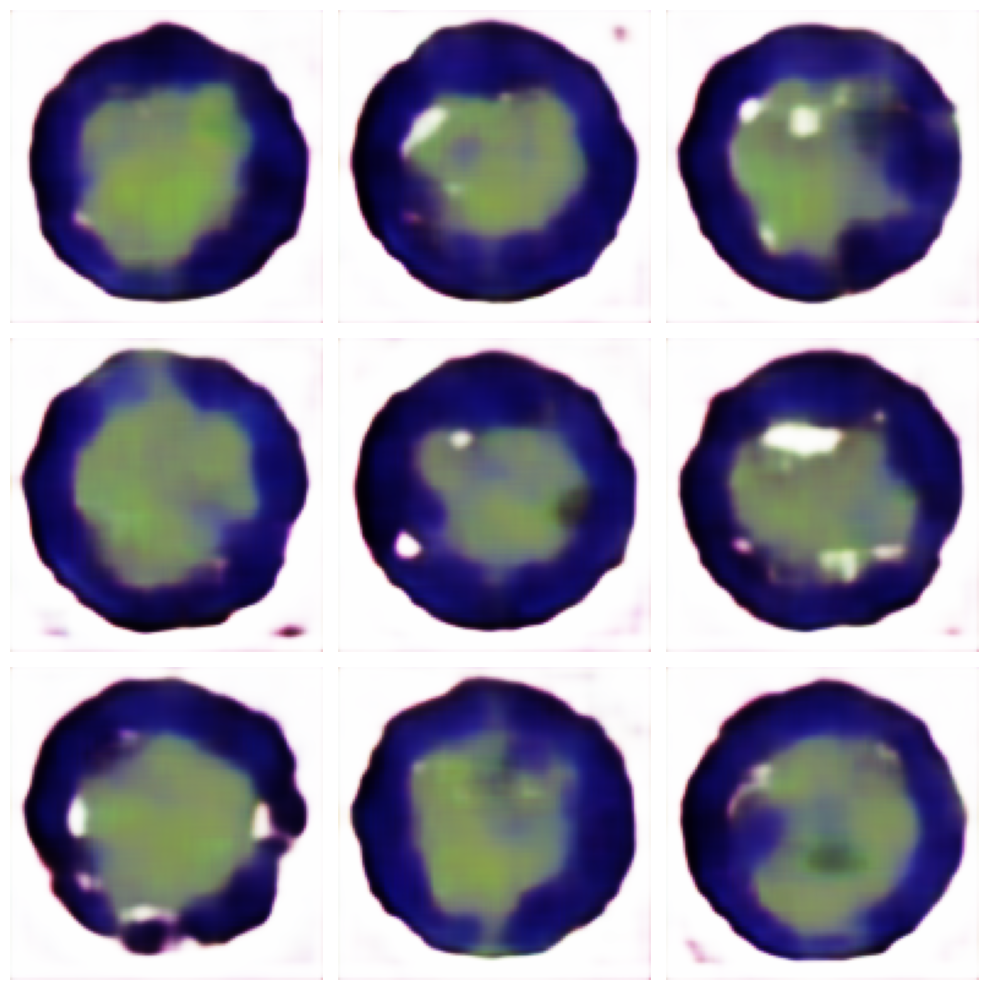

In [20]:
# ==========================================
# 5.11 VISUALIZE FINAL GENERATOR V2 OUTPUTS
# ==========================================

generated_images_v2 = generator_v2(
    FIXED_Z_V2,
    training=False
)

plt.figure(figsize=(10, 10))

for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(generated_images_v2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()